
# Weather Analysis & Automated Reporting Pipeline

## 1. Project Overview

This project demonstrates a beginner-level data analysis and reporting pipeline using Python.

The analysis uses historical daily minimum temperatures recorded in Melbourne, Australia, from 1981 to 1990.

### Project Objectives
- Import historical temperature data.
- Examine data quality and consistency.
- Calculate descriptive statistics.
- Identify temperature patterns and seasonal variation.
- Compare 7-day and 30-day moving averages.
- Generate visualizations and a statistical report.
- Demonstrate optional automated email delivery.

### Dataset
**Source:** Daily Minimum Temperatures in Melbourne, Australia  
**Period:** 1981–1990  
**Frequency:** Daily  
**Measurement:** Minimum temperature (°C)

### Tools and Libraries
- Python
- pandas
- NumPy
- Matplotlib
- seaborn
- pathlib
- smtplib

### Research Questions
1. What is the typical daily minimum temperature?
2. How much do minimum temperatures vary?
3. Are there seasonal temperature patterns?
4. How do short-term and long-term moving averages differ?

### Hypotheses

**H1:** Daily minimum temperatures exhibit seasonal variation.

**H2:** The 7-day moving average follows short-term changes more closely than the 30-day moving average.

**H3:** Descriptive statistics and visualizations together provide a more complete understanding of temperature variability than a single summary statistic.

These are exploratory hypotheses, not formal statistical tests.


In [23]:

%pip install pandas numpy matplotlib seaborn


In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

# Create output directory
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")
print("Output directory:", OUTPUT_DIR.resolve())


Libraries imported successfully.
Output directory: /content/outputs



## 2. Data Ingestion

### Objective
Import historical temperature observations from a publicly available CSV dataset.

### Methodology
The dataset is retrieved from a public GitHub-hosted CSV file using pandas.

The source contains two columns:
- `Date`: Observation date.
- `Temp`: Daily minimum temperature in degrees Celsius.

### Data Quality Consideration
External data sources may become unavailable or change over time.

The pipeline therefore checks whether the required columns are present before proceeding.


In [25]:

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "jbrownlee/Datasets/master/daily-min-temperatures.csv"
)

try:
    df_raw = pd.read_csv(DATA_URL)

    required_columns = {"Date", "Temp"}

    if not required_columns.issubset(df_raw.columns):
        raise ValueError(
            "Dataset does not contain the expected columns."
        )

    print("Dataset loaded successfully!")
    print("Rows:", len(df_raw))
    print("Columns:", len(df_raw.columns))

except Exception as error:
    raise RuntimeError(
        f"Data ingestion failed: {error}"
    ) from error

display(df_raw.head())


Dataset loaded successfully!
Rows: 3650
Columns: 2


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8



### Data Ingestion Conclusion

The dataset was imported from a public CSV source.

The initial inspection confirms that the expected date and temperature columns are available.

Before performing statistical analysis, the dataset must be checked for missing values, duplicated dates, invalid observations, and chronological consistency.



## 3. Data Quality Assessment

### Objective
Assess the completeness, uniqueness, and structure of the imported dataset.

### Checks Performed
1. Dataset dimensions.
2. Column data types.
3. Missing observations.
4. Duplicate records.
5. Duplicate dates.
6. Validity of date and temperature values.

### Hypothesis
The historical dataset is expected to contain one valid temperature observation per calendar day.

### Why This Matters
Missing observations or duplicate dates may distort summary statistics and rolling-average calculations.


In [26]:

print("DATASET SHAPE")
print(df_raw.shape)

print("\nDATA TYPES")
print(df_raw.dtypes)

print("\nMISSING VALUES")
print(df_raw.isna().sum())

print("\nDUPLICATE ROWS")
print(df_raw.duplicated().sum())

print("\nDUPLICATE DATES")
print(df_raw["Date"].duplicated().sum())

# Check whether dates and temperatures can be converted
parsed_dates = pd.to_datetime(
    df_raw["Date"],
    errors="coerce"
)

parsed_temps = pd.to_numeric(
    df_raw["Temp"],
    errors="coerce"
)

print("\nINVALID DATES")
print(parsed_dates.isna().sum())

print("\nINVALID TEMPERATURES")
print(parsed_temps.isna().sum())

print("\nTEMPERATURE RANGE")
print("Minimum:", parsed_temps.min())
print("Maximum:", parsed_temps.max())


DATASET SHAPE
(3650, 2)

DATA TYPES
Date     object
Temp    float64
dtype: object

MISSING VALUES
Date    0
Temp    0
dtype: int64

DUPLICATE ROWS
0

DUPLICATE DATES
0

INVALID DATES
0

INVALID TEMPERATURES
0

TEMPERATURE RANGE
Minimum: 0.0
Maximum: 26.3


In [27]:

valid_dates = parsed_dates.dropna()

expected_dates = pd.date_range(
    start=valid_dates.min(),
    end=valid_dates.max(),
    freq="D"
)

observed_dates = pd.DatetimeIndex(
    valid_dates.unique()
)

missing_dates = expected_dates.difference(
    observed_dates
)

print("Expected calendar days:", len(expected_dates))
print("Unique observed dates:", len(observed_dates))
print("Missing calendar dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nFirst missing dates:")
    print(missing_dates[:10])


Expected calendar days: 3652
Unique observed dates: 3650
Missing calendar dates: 2

First missing dates:
DatetimeIndex(['1984-12-31', '1988-12-31'], dtype='datetime64[ns]', freq=None)



### Data Quality Conclusion

The dataset was examined for missing values, duplicate observations, invalid data types, and gaps in the daily calendar.

These checks help determine whether the observations can be used reliably for time-series analysis.

**Important:** A missing calendar date is not the same as a missing temperature value in an existing record.

Both issues must be considered before calculating rolling statistics.

The numerical results from the quality checks should be used to confirm whether cleaning is required.



## 4. Data Cleaning and Transformation

### Objective
Prepare the dataset for statistical analysis and time-series visualization.

### Methodology
1. Create a working copy of the original dataset.
2. Convert dates into datetime format.
3. Convert temperature values into numeric format.
4. Remove invalid dates and missing temperature observations.
5. Remove duplicate dates.
6. Sort observations chronologically.
7. Set the date column as the index.

### Assumption
Each date should represent one daily minimum temperature observation.

Duplicate dates will be resolved by retaining the first observation. This is a simple rule for this beginner project and should be reconsidered if conflicting duplicate values are discovered.

Missing temperatures will not be estimated or interpolated.


In [28]:

# Preserve the original dataset
df = df_raw.copy()

# Convert data types
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

df["Temp"] = pd.to_numeric(
    df["Temp"],
    errors="coerce"
)

original_rows = len(df)

# Remove invalid observations
df = df.dropna(subset=["Date", "Temp"])

# Remove duplicate dates
df = df.drop_duplicates(
    subset=["Date"],
    keep="first"
)

# Sort dates
df = df.sort_values("Date")

# Set time-series index
df = df.set_index("Date")

# Check for calendar gaps
full_calendar = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

missing_calendar_dates = full_calendar.difference(
    df.index
)

# Reindex to preserve missing calendar days
df = df.reindex(full_calendar)
df.index.name = "Date"

print("Original rows:", original_rows)
print("Valid observed temperatures:", df["Temp"].count())
print("Removed invalid/duplicate rows:",
      original_rows - df["Temp"].count())
print("Missing calendar days:", len(missing_calendar_dates))

display(df.head())


Original rows: 3650
Valid observed temperatures: 3650
Removed invalid/duplicate rows: 0
Missing calendar days: 2


,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


In [29]:

cleaned_file = OUTPUT_DIR / "cleaned_weather.csv"

df.to_csv(cleaned_file)

print("Cleaned dataset saved to:", cleaned_file)


Cleaned dataset saved to: outputs/cleaned_weather.csv



### Data Cleaning Conclusion

The dataset has been converted into a chronological time-series structure.

The date column is used as the index to support time-based operations.

Invalid observations and duplicate dates are removed, while missing calendar dates are preserved as missing values rather than assigned artificial temperatures.

This approach avoids treating nonconsecutive observations as consecutive calendar days during moving-average calculations.



## 5. Descriptive Statistics

### Objective
Understand the central tendency, dispersion, and distribution of daily minimum temperatures.

### Statistical Measures
- **Mean:** Average observed temperature.
- **Median:** Middle temperature value.
- **Standard deviation:** Typical dispersion around the mean.
- **Variance:** Squared measure of dispersion.
- **Skewness:** Asymmetry of the temperature distribution.
- **Minimum and maximum:** Lowest and highest recorded temperatures.

### Hypothesis
Daily minimum temperatures vary over time and may exhibit a relatively balanced distribution.

### Limitation
A low standard deviation does not automatically imply that temperatures are predictable.

Forecasting accuracy requires additional analysis.


In [30]:

temperature = df["Temp"].dropna()

stats_summary = {
    "Count": temperature.count(),
    "Mean": temperature.mean(),
    "Median": temperature.median(),
    "Standard Deviation": temperature.std(),
    "Variance": temperature.var(),
    "Skewness": temperature.skew(),
    "Minimum": temperature.min(),
    "Maximum": temperature.max(),
    "25th Percentile": temperature.quantile(0.25),
    "75th Percentile": temperature.quantile(0.75)
}

stats_df = pd.DataFrame(
    stats_summary.items(),
    columns=["Statistic", "Value"]
)

display(stats_df.round(2))


,Statistic,Value
0,Count,3650.00
1,Mean,11.18
2,Median,11.00
3,Standard Deviation,4.07
4,Variance,16.58
5,Skewness,0.17
6,Minimum,0.00
7,Maximum,26.30
8,25th Percentile,8.30
9,75th Percentile,14.00


In [31]:

mean_temp = temperature.mean()
median_temp = temperature.median()
std_temp = temperature.std()
skew_temp = temperature.skew()

print("STATISTICAL INTERPRETATION\n")

print(f"Mean daily minimum temperature: {mean_temp:.2f}°C")
print(f"Median daily minimum temperature: {median_temp:.2f}°C")
print(f"Standard deviation: {std_temp:.2f}°C")
print(f"Skewness: {skew_temp:.2f}")

if abs(skew_temp) < 0.5:
    print("Distribution: approximately symmetric")
elif skew_temp > 0:
    print("Distribution: positively skewed")
else:
    print("Distribution: negatively skewed")

print(
    "\nNote: These statistics describe historical "
    "temperature observations, not forecast accuracy."
)


STATISTICAL INTERPRETATION

Mean daily minimum temperature: 11.18°C
Median daily minimum temperature: 11.00°C
Standard deviation: 4.07°C
Skewness: 0.17
Distribution: approximately symmetric

Note: These statistics describe historical temperature observations, not forecast accuracy.



### Statistical Analysis Conclusion

Descriptive statistics provide an overview of historical minimum temperatures.

The mean and median describe central tendency, while standard deviation and variance measure dispersion.

Skewness helps assess whether the distribution is approximately symmetric or has a longer tail on one side.

These measures summarize the full observation period but do not account for seasonal patterns or chronological relationships.

Further visualization is required to investigate those characteristics.



## 6. Exploratory Data Analysis

### Objective
Examine the distribution and variation of daily minimum temperatures.

### Visualizations
1. Histogram with density curve.
2. Boxplot showing median, quartiles, and potential outliers.
3. Daily temperature time-series chart.

### Hypothesis
Temperatures are expected to vary across the observation period, potentially reflecting seasonal changes.

### Analytical Consideration
An unusual temperature observation is not necessarily an incorrect measurement.

Potential outliers should be investigated rather than automatically removed.


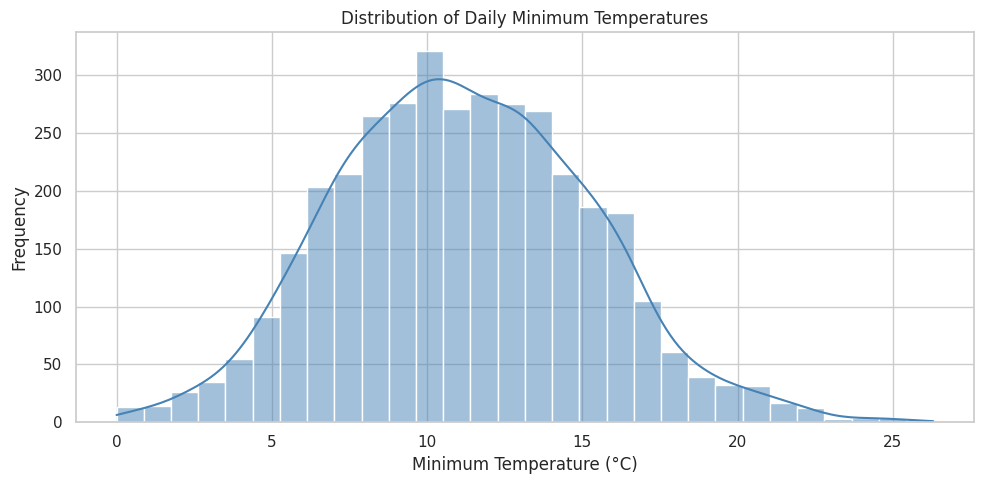

In [32]:

plt.figure(figsize=(10, 5))

sns.histplot(
    temperature,
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Daily Minimum Temperatures")
plt.xlabel("Minimum Temperature (°C)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "temperature_distribution.png",
    dpi=150
)
plt.show()


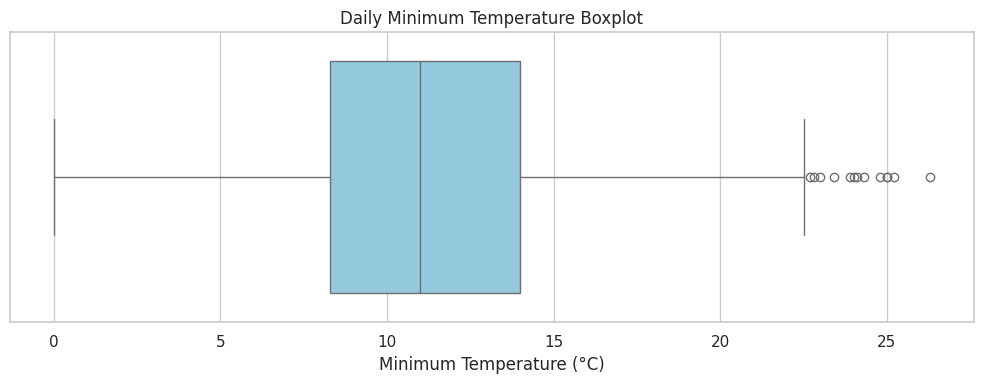

In [33]:

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=temperature,
    color="skyblue"
)

plt.title("Daily Minimum Temperature Boxplot")
plt.xlabel("Minimum Temperature (°C)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "temperature_boxplot.png",
    dpi=150
)
plt.show()


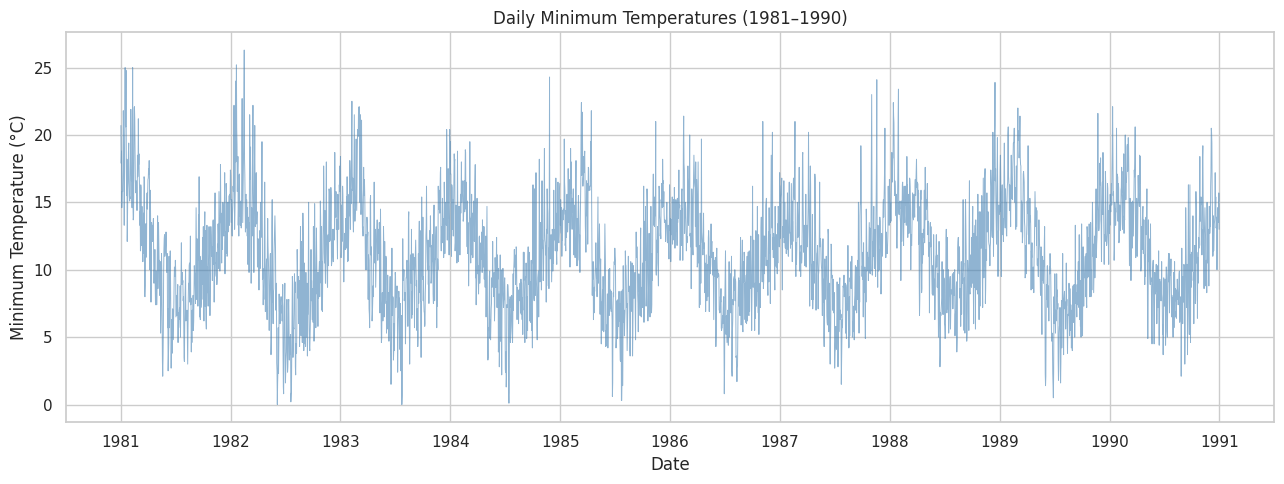

In [34]:

plt.figure(figsize=(13, 5))

plt.plot(
    df.index,
    df["Temp"],
    color="steelblue",
    alpha=0.6,
    linewidth=0.7
)

plt.title("Daily Minimum Temperatures (1981–1990)")
plt.xlabel("Date")
plt.ylabel("Minimum Temperature (°C)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "daily_temperature_trend.png",
    dpi=150
)
plt.show()



### Exploratory Analysis Conclusion

The histogram and boxplot provide complementary views of temperature distribution.

The histogram illustrates the frequency of temperature ranges, while the boxplot highlights the median, interquartile range, and potential outliers.

The daily time-series chart shows how temperatures change over the observation period.

However, the density of daily observations makes longer-term patterns difficult to distinguish.

Moving averages and monthly aggregation will therefore be used to examine trends and seasonality more clearly.



## 7. Moving Average Analysis

### Objective
Smooth daily temperature fluctuations to identify short-term and longer-term patterns.

### Methodology
Two rolling averages are calculated:

- **7-day moving average:** Represents the average temperature over the latest seven calendar days.
- **30-day moving average:** Represents the average temperature over the latest thirty calendar days.

### Hypothesis
The 7-day moving average will respond more quickly to temperature changes, while the 30-day moving average will produce a smoother trend.

### Limitations
Moving averages are descriptive smoothing techniques.

They are not forecasts and may conceal individual extreme observations.

A complete rolling window is required before calculating an average.


In [35]:

df["7_Day_MA"] = df["Temp"].rolling(
    window=7,
    min_periods=7
).mean()

df["30_Day_MA"] = df["Temp"].rolling(
    window=30,
    min_periods=30
).mean()

display(
    df[["Temp", "7_Day_MA", "30_Day_MA"]].head(35)
)


,Temp,7_Day_MA,30_Day_MA
Date,,,
1981-01-01,20.7,NaN,NaN
1981-01-02,17.9,NaN,NaN
1981-01-03,18.8,NaN,NaN
1981-01-04,14.6,NaN,NaN
1981-01-05,15.8,NaN,NaN
1981-01-06,15.8,NaN,NaN
1981-01-07,15.8,17.057143,NaN
1981-01-08,17.4,16.585714,NaN
1981-01-09,21.8,17.142857,NaN


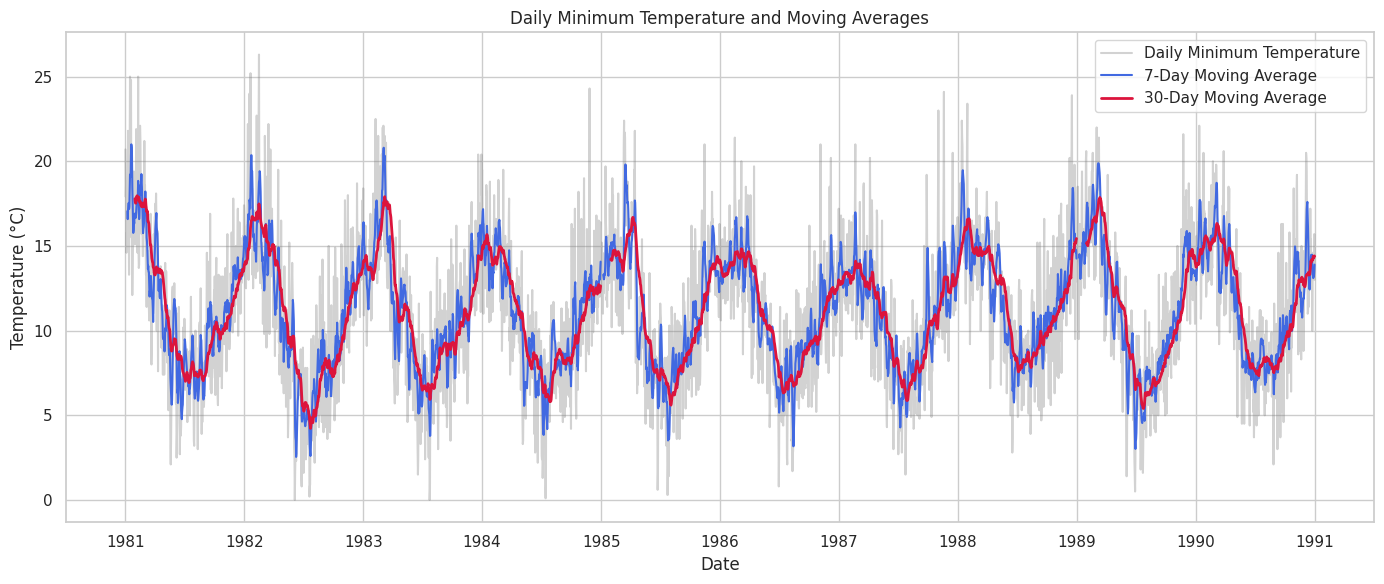

In [36]:

plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["Temp"],
    label="Daily Minimum Temperature",
    color="gray",
    alpha=0.35
)

plt.plot(
    df.index,
    df["7_Day_MA"],
    label="7-Day Moving Average",
    color="royalblue",
    linewidth=1.5
)

plt.plot(
    df.index,
    df["30_Day_MA"],
    label="30-Day Moving Average",
    color="crimson",
    linewidth=2
)

plt.title("Daily Minimum Temperature and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "moving_averages.png",
    dpi=150
)
plt.show()



### Moving Average Conclusion

The 7-day and 30-day moving averages help visualize temperature patterns at different time scales.

The 7-day average is more sensitive to short-term changes, while the 30-day average smooths more daily fluctuations.

The comparison illustrates how the choice of rolling-window size affects the visibility of variation.

These averages describe historical patterns and should not be interpreted as evidence that future temperatures can be predicted accurately.



## 8. Seasonal Temperature Analysis

### Objective
Investigate whether minimum temperatures vary systematically across calendar months.

### Hypothesis
Monthly minimum temperatures exhibit seasonal variation, with relatively warmer nights during the Australian summer and cooler nights during winter.

### Methodology
Calculate average minimum temperatures for each calendar month across the observation period.

### Limitation
Monthly averages describe recurring seasonal patterns but do not explain the physical causes of individual temperature changes.


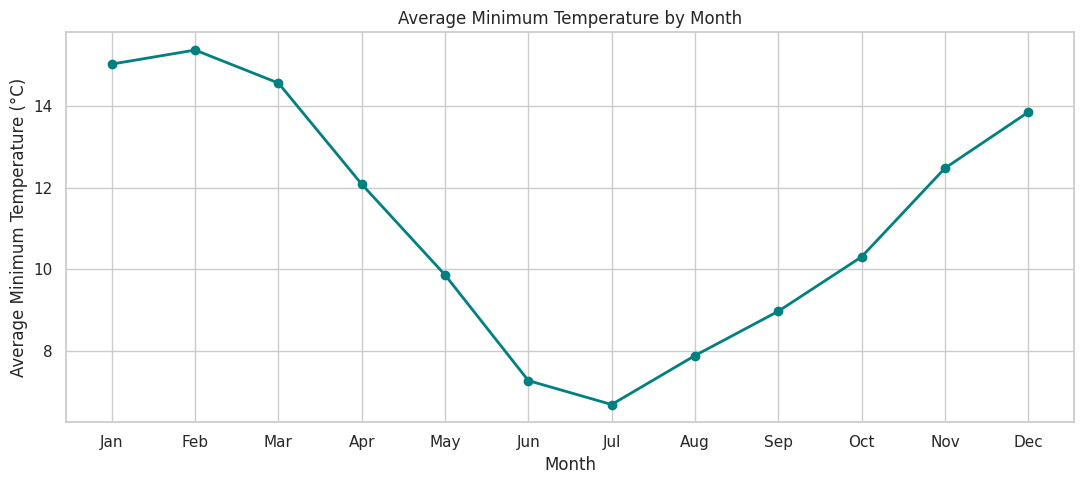

,Temp
Month,
1,15.03
2,15.37
3,14.57
4,12.09
5,9.87
6,7.28
7,6.69
8,7.89
9,8.98


In [37]:

# Add calendar information
df["Year"] = df.index.year
df["Month"] = df.index.month

monthly_avg = df.groupby("Month")["Temp"].mean()

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    linewidth=2,
    color="teal"
)

plt.xticks(
    range(1, 13),
    month_names
)

plt.title("Average Minimum Temperature by Month")
plt.xlabel("Month")
plt.ylabel("Average Minimum Temperature (°C)")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "monthly_seasonality.png",
    dpi=150
)
plt.show()

display(monthly_avg.round(2))


In [38]:

annual_summary = df.groupby("Year")["Temp"].agg(
    ["mean", "min", "max", "std", "count"]
)

annual_summary.columns = [
    "Mean",
    "Minimum",
    "Maximum",
    "Std_Dev",
    "Observations"
]

display(annual_summary.round(2))

annual_summary.to_csv(
    OUTPUT_DIR / "annual_temperature_summary.csv"
)


,Mean,Minimum,Maximum,Std_Dev,Observations
Year,,,,,
1981,11.52,2.1,25.0,4.34,365
1982,10.78,0.0,26.3,4.81,365
1983,11.19,0.0,22.5,4.19,365
1984,10.59,0.1,24.3,3.73,365
1985,11.14,0.3,22.4,4.14,365
1986,10.80,0.8,21.4,3.61,365
1987,10.85,1.5,24.1,3.63,365
1988,11.97,2.8,23.9,3.75,365
1989,11.26,0.5,22.0,4.33,365



### Seasonal Analysis Conclusion

Monthly aggregation provides a clearer view of recurring temperature patterns.

The monthly chart can be used to assess whether minimum temperatures tend to be higher during Australian summer months and lower during winter months.

Annual summaries also provide an overview of year-to-year variability.

The analysis is descriptive and does not establish a statistically significant long-term climate trend.

A longer observation period and additional statistical methods would be required for that purpose.



## 9. Automated Report Generation

### Objective
Convert statistical findings into a reusable text report.

### Methodology
The pipeline combines descriptive statistics, data quality information, and the observation period into a formatted report.

The report is saved as a text file and can be regenerated whenever the notebook is executed.

### Expected Output
`outputs/weather_summary_report.txt`

### Automation Scope
Report generation is automatic when this notebook runs.

Running the notebook on a recurring schedule requires an additional scheduling mechanism.


In [39]:

report_date = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

latest_observation = df["Temp"].last_valid_index()

report = f"""
WEATHER ANALYSIS & AUTOMATED REPORT
========================================

Report Generated: {report_date}

DATASET INFORMATION
----------------------------------------
Location: Melbourne, Australia
Period: {df.index.min().date()} to {df.index.max().date()}
Valid Observations: {temperature.count()}
Missing Calendar Days: {len(missing_calendar_dates)}

DESCRIPTIVE STATISTICS
----------------------------------------
Mean Temperature: {mean_temp:.2f} °C
Median Temperature: {median_temp:.2f} °C
Standard Deviation: {std_temp:.2f} °C
Variance: {temperature.var():.2f} °C²
Skewness: {skew_temp:.2f}
Minimum Temperature: {temperature.min():.2f} °C
Maximum Temperature: {temperature.max():.2f} °C

TIME-SERIES ANALYSIS
----------------------------------------
7-Day Moving Average: Calculated
30-Day Moving Average: Calculated
Monthly Seasonality: Analyzed
Annual Temperature Summary: Generated

Latest Observation Date:
{latest_observation.date()}

ANALYTICAL CONCLUSION
----------------------------------------
Historical daily minimum temperatures show
variation across the observation period.

Descriptive statistics summarize the
distribution of temperatures.

Moving averages help visualize short-term
and longer-term patterns.

Monthly aggregation supports the exploration
of recurring seasonal variation.

LIMITATIONS
----------------------------------------
1. The dataset contains historical observations.
2. Moving averages are not forecasts.
3. Descriptive statistics do not establish
   temperature predictability.
4. Results apply to the analyzed location
   and observation period.
5. This report is regenerated on execution;
   it does not automatically acquire new
   observations beyond the source dataset.

========================================
END OF REPORT
"""

report_path = OUTPUT_DIR / "weather_summary_report.txt"

report_path.write_text(
    report,
    encoding="utf-8"
)

print(report)
print("Report saved to:", report_path)



WEATHER ANALYSIS & AUTOMATED REPORT

Report Generated: 2026-10-19 01:49:12

DATASET INFORMATION
----------------------------------------
Location: Melbourne, Australia
Period: 1981-01-01 to 1990-12-31
Valid Observations: 3650
Missing Calendar Days: 2

DESCRIPTIVE STATISTICS
----------------------------------------
Mean Temperature: 11.18 °C
Median Temperature: 11.00 °C
Standard Deviation: 4.07 °C
Variance: 16.58 °C²
Skewness: 0.17
Minimum Temperature: 0.00 °C
Maximum Temperature: 26.30 °C

TIME-SERIES ANALYSIS
----------------------------------------
7-Day Moving Average: Calculated
30-Day Moving Average: Calculated
Monthly Seasonality: Analyzed
Annual Temperature Summary: Generated

Latest Observation Date:
1990-12-31

ANALYTICAL CONCLUSION
----------------------------------------
Historical daily minimum temperatures show
variation across the observation period.

Descriptive statistics summarize the
distribution of temperatures.

Moving averages help visualize short-term
and longer-


### Report Generation Conclusion

The statistical report was generated programmatically from the processed dataset.

This reduces the need to manually transfer statistical values into a separate document.

The report contains the observation period, descriptive statistics, analytical summary, and methodological limitations.

The same process can be repeated when the pipeline is executed again.

This demonstrates basic reporting automation, although the historical dataset itself does not update with current weather conditions.



## 10. Email Report Delivery

### Objective
Demonstrate how Python can distribute a generated statistical report through email.

### Methodology
The script:
1. Reads email configuration from environment variables.
2. Creates a multipart email message.
3. Attaches the statistical report.
4. Attaches the moving-average visualization.
5. Sends the message through Gmail SMTP using TLS.

### Security Consideration
Email credentials must not be hardcoded or committed to GitHub.

The demonstration requires the user to configure their own email credentials.

### Limitation
Email delivery occurs only when the sending function is executed.

A scheduling system is needed for unattended recurring delivery.


In [44]:

import smtplib
from email.message import EmailMessage
from getpass import getpass

# Read credentials from environment variables
sender_email = os.getenv("WEATHER_SENDER_EMAIL")
receiver_email = os.getenv("WEATHER_RECEIVER_EMAIL")
app_password = os.getenv("WEATHER_EMAIL_APP_PASSWORD")

# Prompt for credentials if not already configured
if not sender_email:
    sender_email = input("Sender Gmail address: ").strip()

if not receiver_email:
    receiver_email = input("Recipient email address: ").strip()

if not app_password:
    app_password = getpass("Gmail App Password: ")

print("Email configuration prepared.")


Sender Gmail address: nuruldalia01@gmail.com
Recipient email address: nuruldalia01@gmail.com
Gmail App Password: ··········
Email configuration prepared.


In [48]:

def send_weather_report(
    sender,
    recipient,
    password,
    report_file,
    chart_file
):
    # Create email
    message = EmailMessage()

    message["Subject"] = (
        "Weather Analysis - Historical Temperature Report"
    )
    message["From"] = sender
    message["To"] = recipient

    message.set_content(
        "Hello,\n\n"
        "Attached is the automated historical "
        "temperature analysis report.\n\n"
        "This report includes descriptive statistics "
        "and a moving-average visualization.\n\n"
        "Regards,\nWeather Analysis Pipeline"
    )

    # Attach text report
    message.add_attachment(
        report_file.read_bytes(),
        maintype="text",
        subtype="plain",
        filename=report_file.name
    )

    # Attach visualization
    message.add_attachment(
        chart_file.read_bytes(),
        maintype="image",
        subtype="png",
        filename=chart_file.name
    )

    # Connect and send securely
    with smtplib.SMTP(
        "smtp.gmail.com",
        587,
        timeout=30
    ) as server:

        server.ehlo()
        server.starttls()
        server.ehlo()

        server.login(sender, password)
        server.send_message(message)

    print("Email report sent successfully!")


chart_path = OUTPUT_DIR / "moving_averages.png"

# Set True only when ready to send an email
SEND_EMAIL = False

if SEND_EMAIL:
    send_weather_report(
        sender_email,
        receiver_email,
        app_password,
        report_path,
        chart_path
    )
else:
    print(
        "Email sending disabled. "
        "Set SEND_EMAIL = True to send the report."
    )


Email sending disabled. Set SEND_EMAIL = True to send the report.



### Email Automation Conclusion

The email delivery function demonstrates how generated analysis outputs can be distributed using Python.

The script uses SMTP with TLS to send the report and chart as attachments.

Email credentials are not stored directly in the source code.

The function can be reused as part of a scheduled workflow.

Successful delivery must be verified through an actual test before describing the email automation as operational.



## 11. Pipeline Validation

### Objective
Verify that the processed dataset and required output files meet basic expectations.

### Validation Checks
- The dataset contains valid temperature observations.
- Dates are ordered chronologically.
- The index does not contain duplicate dates.
- Temperature values are numeric.
- The 7-day and 30-day moving-average columns exist.
- The statistical report and required visualizations were generated.

### Expected Outcome
All checks should pass when the notebook has been executed successfully from beginning to end.

These checks provide basic validation but are not a replacement for a comprehensive automated test suite.


In [43]:

# Validate dataset
assert not df.empty, "Dataset is empty."

assert df.index.is_monotonic_increasing, (
    "Dates are not sorted."
)

assert df.index.is_unique, (
    "Duplicate dates detected."
)

assert pd.api.types.is_numeric_dtype(df["Temp"]), (
    "Temperature column is not numeric."
)

assert df["Temp"].notna().any(), (
    "No valid temperatures found."
)

assert "7_Day_MA" in df.columns
assert "30_Day_MA" in df.columns

# Validate output files
required_outputs = [
    "cleaned_weather.csv",
    "temperature_distribution.png",
    "temperature_boxplot.png",
    "daily_temperature_trend.png",
    "moving_averages.png",
    "monthly_seasonality.png",
    "annual_temperature_summary.csv",
    "weather_summary_report.txt"
]

for filename in required_outputs:
    file_path = OUTPUT_DIR / filename

    assert file_path.is_file(), (
        f"Missing output: {filename}"
    )

    assert file_path.stat().st_size > 0, (
        f"Empty output: {filename}"
    )

print("All basic pipeline validation checks passed!")


All basic pipeline validation checks passed!



### Pipeline Validation Conclusion

Basic validation checks were implemented to confirm that the processed data and generated outputs satisfy expected structural requirements.

The checks help detect missing output files, invalid data types, duplicate dates, and incomplete execution.

This improves confidence in the pipeline's repeatability.

However, the validation does not guarantee that every statistical interpretation is correct or that external services will always be available.



## 12. Final Conclusion

### Project Summary

This project demonstrates a beginner-level data analysis and automated reporting workflow using historical daily minimum temperature observations.

The pipeline covers data ingestion, data quality assessment, cleaning, descriptive statistics, exploratory analysis, moving averages, seasonal analysis, and report generation.

An optional email function demonstrates how analytical outputs can be distributed automatically when the sending process is executed.

### Key Analytical Findings

**1. Temperature Distribution**

Descriptive statistics summarize the central tendency and variability of daily minimum temperatures.

**2. Time-Series Patterns**

The 7-day and 30-day moving averages provide different levels of smoothing, allowing short-term changes and longer-term patterns to be compared.

**3. Seasonal Variation**

Monthly aggregation provides a way to investigate recurring seasonal temperature differences.

**4. Automated Reporting**

The report generator converts calculated statistics into a reusable text report and saves supporting visualizations.

### Limitations

- The dataset contains historical observations rather than live weather measurements.
- Moving averages are descriptive and do not provide forecasting accuracy.
- The pipeline does not automatically update its dataset with current weather information.
- Email delivery requires valid credentials and a successful SMTP connection.
- Scheduled execution is not implemented in this notebook.
- Statistical conclusions apply only to the dataset and period analyzed.

### Future Improvements

Potential future enhancements include:
- Integrating a live weather API.
- Scheduling the pipeline with a task scheduler.
- Introducing logging and additional automated tests.
- Comparing historical weather patterns across multiple locations.

### Final Statement

The project demonstrates foundational Python data analysis skills and practical report automation.

It provides an introductory example of how raw data can be transformed into validated, visualized, and documented analytical outputs.
